## Introduction
- The Spaceship Titanic was on a journey when a collision with a spacetime anomaly caused many passengers to be transported to another dimension.
- This project uses passenger details such as age, home planet, cabin, and spending to explore patterns related to transportation.
- Python and machine learning are used to analyze the data and predict which passengers were transported.

In [1]:
# Importing required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

#reading csv 
df = pd.read_csv("D:/Pragati_SEM5/Spaceship-Titanic-ML/data/train.csv")
# Displaying the first five rows of the dataset
df.head()



,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


## Problem Statement
- The challenge is to predict which passengers were transported based on their available information.
- The dataset contains missing values and different types of passenger attributes that require preprocessing.
- Four machine learning models are developed and compared to identify the best-performing model for this prediction task.

## Project Objectives

- To understand the Spaceship Titanic dataset and passenger characteristics.
- To explore patterns related to passenger transportation.
- To clean the data and handle missing values and duplicate records.
- To create useful features through feature engineering.
- To build and compare four machine learning classification models.
- To evaluate models using accuracy, precision, recall, and F1-score.
- To identify the best-performing model.

In [2]:
df.shape

(8693, 14)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


In [4]:
df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [5]:
df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Name', 'Transported'],
      dtype='object')

In [6]:
# Checking for duplicate rows in the dataset
df.duplicated().sum()

np.int64(0)

In [7]:
# Checking the number of missing values in each column
df.isnull().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

In [8]:
# Counting passengers who were transported and those who were not
df['Transported'].value_counts()

Transported
True     4378
False    4315
Name: count, dtype: int64

In [9]:
# Checking unique values in categorical columns

print("HomePlanet:", df['HomePlanet'].unique())
print("CryoSleep:", df['CryoSleep'].unique())
print("Destination:", df['Destination'].unique())
print("VIP:", df['VIP'].unique())

HomePlanet: ['Europa' 'Earth' 'Mars' nan]
CryoSleep: [False True nan]
Destination: ['TRAPPIST-1e' 'PSO J318.5-22' '55 Cancri e' nan]
VIP: [False True nan]


In [10]:
# Checking the number of unique values in categorical columns
print("HomePlanet:", df['HomePlanet'].nunique())
print("CryoSleep:", df['CryoSleep'].nunique())
print("Destination:", df['Destination'].nunique())
print("VIP:", df['VIP'].nunique())

HomePlanet: 3
CryoSleep: 2
Destination: 3
VIP: 2


In [11]:
# Checking missing values in each categorical column

print("HomePlanet missing:", df['HomePlanet'].isnull().sum())
print("CryoSleep missing:", df['CryoSleep'].isnull().sum())
print("Destination missing:", df['Destination'].isnull().sum())
print("VIP missing:", df['VIP'].isnull().sum())

HomePlanet missing: 201
CryoSleep missing: 217
Destination missing: 182
VIP missing: 203


In [12]:
# Calculating missing-value counts and percentages

# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_count / len(df)) * 100

# Combine both results into a summary table
missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage': missing_percentage
})

# Display only columns that contain missing values
missing_summary = missing_summary[missing_summary['Missing Count'] > 0]

# Sort columns by missing percentage in descending order
missing_summary = missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

missing_summary

,Missing Count,Missing Percentage
CryoSleep,217,2.496261
ShoppingMall,208,2.392730
VIP,203,2.335212
HomePlanet,201,2.312205
Name,200,2.300702
Cabin,199,2.289198
VRDeck,188,2.162660
FoodCourt,183,2.105142
Spa,183,2.105142
Destination,182,2.093639


### Missing Value Analysis

The dataset contains missing values in 12 out of 14 columns. The number of missing values ranges from 179 to 217 per column, representing approximately 2.06% to 2.50% of the total 8,693 records. The `CryoSleep` column has the highest number of missing values, while `Age` has the lowest among the affected columns. Since the missing percentage is relatively low across these features, retaining the columns and handling missing values during preprocessing is a reasonable approach.

In [13]:
# Checking the number of duplicate rows in the dataset

duplicate_count = df.duplicated().sum()

# Displaying the result
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


### Duplicate Record Analysis

The dataset was checked for duplicate rows using the `duplicated()` method. The analysis identified zero duplicate rows among the 8,693 records. Therefore, no rows need to be removed due to exact duplication at this stage.

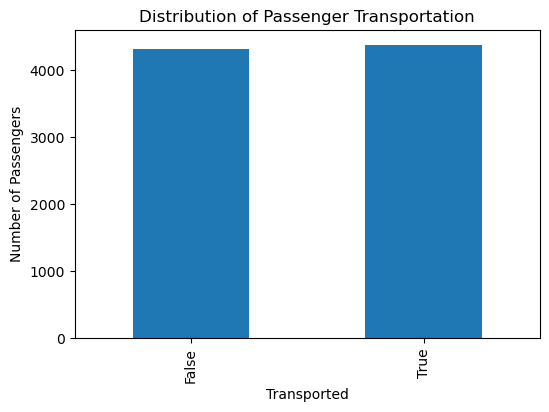

In [14]:
# Counting passengers in each target class
transport_counts = df['Transported'].value_counts().sort_index()

# Creating a bar chart
plt.figure(figsize=(6, 4))
transport_counts.plot(kind='bar')

# Adding chart labels and title
plt.title("Distribution of Passenger Transportation")
plt.xlabel("Transported")
plt.ylabel("Number of Passengers")

plt.show()

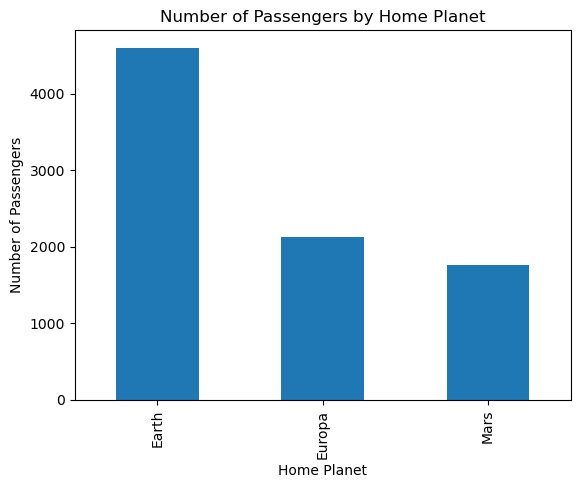

In [15]:
# Counting passengers from each home planet
df['HomePlanet'].value_counts().plot(kind='bar')

# Adding chart labels and title
plt.title("Number of Passengers by Home Planet")
plt.xlabel("Home Planet")
plt.ylabel("Number of Passengers")

plt.show()

In [16]:
# Counting passengers from each home planet
df['HomePlanet'].value_counts()

HomePlanet
Earth     4602
Europa    2131
Mars      1759
Name: count, dtype: int64

**Observation:** Earth has the highest number of passengers (4,602), followed by Europa (2,131) and Mars (1,759).

**Conclusion:** Most passengers with a recorded HomePlanet are from Earth.

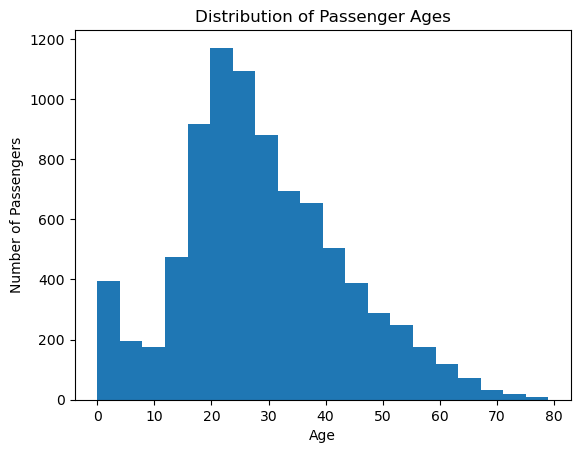

In [17]:
# Creating a histogram to visualize passenger ages
df['Age'].plot(kind='hist', bins=20)

# Adding chart labels and title
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

**Age Distribution Analysis**

The histogram shows that passenger ages are concentrated mainly between 18 and 30 years, with the highest frequency around the early twenties. The number of passengers generally decreases at older ages. The dataset includes both children and elderly passengers, with fewer passengers at the higher end of the age range.

In [18]:
# Calculating the average passenger age
df['Age'].mean()

np.float64(28.82793046746535)

In [19]:
# Calculating the median passenger age
df['Age'].median()

27.0

**Mean and Median Age Analysis**

The mean passenger age is approximately 28.83 years, while the median is 27 years. Since the mean is greater than the median, the age distribution may be positively skewed, with higher ages pulling the average upward. The median provides a useful measure of the typical passenger age because it is less sensitive to extreme values.

In [20]:
# Finding the minimum and maximum passenger ages
print("Youngest passenger age:", df['Age'].min())
print("Oldest passenger age:", df['Age'].max())

Youngest passenger age: 0.0
Oldest passenger age: 79.0


**Passenger Age Range Analysis**

The minimum recorded passenger age is 0 years, while the maximum is 79 years. Therefore, the recorded ages span 79 years. The dataset includes passengers ranging from infants to elderly individuals. These values should be retained unless further investigation identifies a data-quality issue.

In [21]:
# Calculating RoomService spending median
df['RoomService'].median()

0.0

In [22]:
# Calculating average RoomService spending
df['RoomService'].mean()

np.float64(224.687617481203)

**RoomService Spending Analysis**

The average RoomService spending is approximately 224.69 units among passengers with available records. The median spending is zero, indicating that at least half of the passengers with recorded values spent nothing on RoomService. The mean being substantially higher than the median suggests that some passengers have considerably higher spending. Further analysis is needed to investigate whether RoomService spending is associated with transportation.

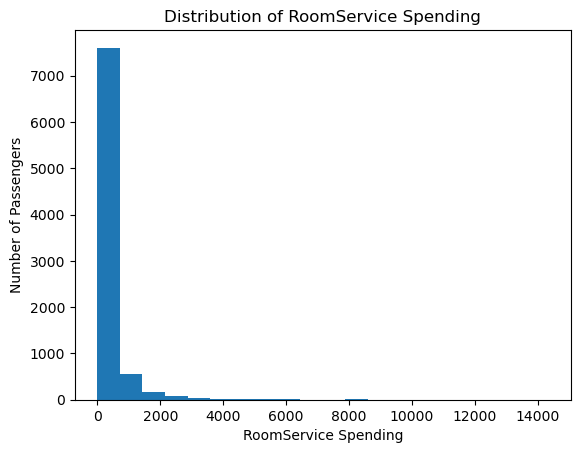

In [23]:
# Visualizing RoomService spending distribution
df['RoomService'].plot(kind='hist', bins=20)

# Adding chart labels and title
plt.title("Distribution of RoomService Spending")
plt.xlabel("RoomService Spending")
plt.ylabel("Number of Passengers")

plt.show()

RoomService spending is unevenly distributed, with many zero values and a small number of high spending observations. 

#Preprocessing

In [24]:
# Checking data types and missing values before preprocessing
print(df.dtypes)

PassengerId      object
HomePlanet       object
CryoSleep        object
Cabin            object
Destination      object
Age             float64
VIP              object
RoomService     float64
FoodCourt       float64
ShoppingMall    float64
Spa             float64
VRDeck          float64
Name             object
Transported        bool
dtype: object


In [25]:
print("\nMissing values in each column:")
print(df.isnull().sum())


Missing values in each column:
PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64


In [26]:
# Creating a copy of the original dataset for preprocessing
data = df.copy()

# Displaying the first five rows
data.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


Feature Engineering:

In [27]:
# Extracting group information from PassengerId
data[['GroupId', 'GroupMember']] = data['PassengerId'].str.split('_', expand=True)

# Extracting deck, cabin number, and side from Cabin
data[['Deck', 'CabinNumber', 'Side']] = data['Cabin'].str.split('/', expand=True)

# Displaying the newly created features
data[['PassengerId', 'GroupId', 'GroupMember',
      'Cabin', 'Deck', 'CabinNumber', 'Side']].head()

,PassengerId,GroupId,GroupMember,Cabin,Deck,CabinNumber,Side
0,0001_01,0001,01,B/0/P,B,0,P
1,0002_01,0002,01,F/0/S,F,0,S
2,0003_01,0003,01,A/0/S,A,0,S
3,0003_02,0003,02,A/0/S,A,0,S
4,0004_01,0004,01,F/1/S,F,1,S


In [28]:
# Counting the number of passengers in each group
group_sizes = data['GroupId'].value_counts()
# Adding the group size as a new feature
data['GroupSize'] = data['GroupId'].map(group_sizes)
# Converting cabin number into a numeric column
data['CabinNumber'] = pd.to_numeric(#text into numeric
    data['CabinNumber'], errors='coerce' #It converts invalid values
                                    # into NaN instead of raising an error.
)

In [29]:
# Displaying the new features
data[['PassengerId', 'GroupId', 'GroupSize',
      'CabinNumber', 'Deck', 'Side']].head()

,PassengerId,GroupId,GroupSize,CabinNumber,Deck,Side
0,0001_01,0001,1,0.0,B,P
1,0002_01,0002,1,0.0,F,S
2,0003_01,0003,2,0.0,A,S
3,0003_02,0003,2,0.0,A,S
4,0004_01,0004,1,1.0,F,S


In [30]:
# Removing unnecessary columns after feature engineering
data = data.drop(columns=[
    'PassengerId', 'GroupId', 'GroupMember',
    'Cabin', 'Name'
])

# Separating input features (X) and target variable (y)
X = data.drop(columns=['Transported'])
y = data['Transported'].astype(int)

# Checking the shape of the input features and target
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Displaying the first five rows of input features
X.head()

Features shape: (8693, 14)
Target shape: (8693,)


,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Deck,CabinNumber,Side,GroupSize
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,B,0.0,P,1
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,F,0.0,S,1
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,A,0.0,S,2
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,A,0.0,S,2
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,F,1.0,S,1


In [31]:

# Importing the function to split the dataset
from sklearn.model_selection import train_test_split

# Splitting the data into 80% training and 20% testing
# stratify=y keeps the target class proportions similar in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y #eeps the proportion of transported and 
                 #non-transported passengers approximately the same in both sets.
)

# Checking the sizes of the training and testing sets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (6954, 14)
Testing features: (1739, 14)
Training target: (6954,)
Testing target: (1739,)


In [32]:

# Creating copies so the original split data remains unchanged
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

# Identifying numerical columns
numeric_features = X_train_clean.select_dtypes(
    include=['int64', 'float64']
).columns

# Identifying categorical columns
categorical_features = X_train_clean.select_dtypes(
    include=['object', 'bool']
).columns

# Filling missing numerical values using training medians
for col in numeric_features:
    median_value = X_train_clean[col].median()
    X_train_clean[col] = X_train_clean[col].fillna(median_value)
    X_test_clean[col] = X_test_clean[col].fillna(median_value)

# Filling missing categorical values using training modes
for col in categorical_features:
    mode_value = X_train_clean[col].mode()[0]
    X_train_clean[col] = X_train_clean[col].fillna(mode_value)
    X_test_clean[col] = X_test_clean[col].fillna(mode_value)

# Checking whether missing values remain
print("Missing values in training data:", X_train_clean.isnull().sum().sum())
print("Missing values in testing data:", X_test_clean.isnull().sum().sum())


Missing values in training data: 0
Missing values in testing data: 0


C:\Users\Ptrip\AppData\Local\Temp\ipykernel_10460\3390408649.py:24: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train_clean[col] = X_train_clean[col].fillna(mode_value)
C:\Users\Ptrip\AppData\Local\Temp\ipykernel_10460\3390408649.py:25: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test_clean[col] = X_test_clean[col].fillna(mode_value)


In [33]:

# Importing LabelEncoder
from sklearn.preprocessing import LabelEncoder

# Creating copies of the cleaned datasets
X_train_encoded = X_train_clean.copy()
X_test_encoded = X_test_clean.copy()

# Encoding categorical columns into numbers
for col in categorical_features:
    encoder = LabelEncoder()

    # Learning categories from training data
    X_train_encoded[col] = encoder.fit_transform(X_train_clean[col].astype(str))

    # Converting testing categories using the same learned mapping
    known_categories = set(encoder.classes_)

    X_test_encoded[col] = X_test_clean[col].astype(str).apply(
        lambda value: encoder.transform([value])[0]
        if value in known_categories else -1
    )

# Checking the encoded datasets
print("Training data shape:", X_train_encoded.shape)
print("Testing data shape:", X_test_encoded.shape)

# Displaying the first five rows
X_train_encoded.head()


Training data shape: (6954, 14)
Testing data shape: (1739, 14)


,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Deck,CabinNumber,Side,GroupSize
3600,0,0,2,0.0,0,0.0,0.0,0.0,0.0,0.0,6,630.0,1,7
1262,0,1,2,17.0,0,0.0,0.0,0.0,0.0,0.0,6,201.0,1,1
8612,0,0,1,35.0,0,0.0,0.0,0.0,0.0,0.0,6,1483.0,1,1
5075,1,1,0,26.0,0,0.0,0.0,0.0,0.0,0.0,3,164.0,1,1
4758,0,0,2,13.0,0,0.0,0.0,60.0,1.0,5147.0,6,818.0,0,1


In [34]:

# Importing StandardScaler to scale numerical features
from sklearn.preprocessing import StandardScaler

# Selecting numerical columns for scaling
numeric_features = X_train_encoded.select_dtypes(
    include=['int64', 'float64']
).columns

# Creating the scaler
scaler = StandardScaler()

# Learning scaling values from training data and transforming it
X_train_encoded[numeric_features] = scaler.fit_transform(
    X_train_encoded[numeric_features]
)

# Applying the same scaling values to testing data
X_test_encoded[numeric_features] = scaler.transform(
    X_test_encoded[numeric_features]
)

# Checking the scaled training data
X_train_encoded.head()


,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Deck,CabinNumber,Side,GroupSize
3600,-0.817594,-0.734286,0.626441,-1.996149,-0.152969,-0.33634,-0.279076,-0.305732,-0.267311,-0.264632,0.951274,0.071038,0.972761,3.130413
1262,-0.817594,1.361866,0.626441,-0.811703,-0.152969,-0.33634,-0.279076,-0.305732,-0.267311,-0.264632,0.951274,-0.777867,0.972761,-0.650221
8612,-0.817594,-0.734286,-0.597574,0.442416,-0.152969,-0.33634,-0.279076,-0.305732,-0.267311,-0.264632,0.951274,1.758954,0.972761,-0.650221
5075,0.436940,1.361866,-1.821589,-0.184643,-0.152969,-0.33634,-0.279076,-0.305732,-0.267311,-0.264632,-0.755277,-0.851082,0.972761,-0.650221
4758,-0.817594,-0.734286,0.626441,-1.090396,-0.152969,-0.33634,-0.279076,-0.195161,-0.266427,4.423937,0.951274,0.443052,-1.028002,-0.650221


In [35]:
# Creating the Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_train_encoded, y_train)
logistic_predictions = logistic_model.predict(X_test_encoded)
print(logistic_predictions[:10])

[1 1 0 1 0 1 1 1 0 1]


In [36]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_encoded, y_train)
knn_predictions = knn_model.predict(X_test_encoded)
print(knn_predictions[:10])

[1 1 0 1 0 1 1 0 0 1]


In [37]:
nb_model = GaussianNB()
nb_model.fit(X_train_encoded, y_train)
nb_predictions = nb_model.predict(X_test_encoded)
print(nb_predictions[:10])

[1 1 0 1 0 1 1 1 0 1]


In [38]:
decision_tree_model = DecisionTreeClassifier(random_state=42)
decision_tree_model.fit(X_train_encoded, y_train)
decision_tree_predictions = decision_tree_model.predict(X_test_encoded)
print(decision_tree_predictions[:10])

[1 1 1 1 1 1 1 0 0 0]


In [39]:
# Storing actual and predicted values for all models
models_predictions = {
    "Logistic Regression": logistic_predictions,
    "KNN": knn_predictions,
    "Gaussian Naive Bayes": nb_predictions,
    "Decision Tree": decision_tree_predictions
}

# Evaluating each model
for name, predictions in models_predictions.items():
    print("\nModel:", name)
    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print("Precision:", round(precision_score(y_test, predictions), 4))
    print("Recall:", round(recall_score(y_test, predictions), 4))
    print("F1-score:", round(f1_score(y_test, predictions), 4))


Model: Logistic Regression
Accuracy: 0.7803
Precision: 0.7782
Recall: 0.7888
F1-score: 0.7834

Model: KNN
Accuracy: 0.7769
Precision: 0.7891
Recall: 0.7603
F1-score: 0.7744

Model: Gaussian Naive Bayes
Accuracy: 0.701
Precision: 0.6402
Recall: 0.9281
F1-score: 0.7577

Model: Decision Tree
Accuracy: 0.7412
Precision: 0.7443
Recall: 0.7409
F1-score: 0.7426


In [40]:
# Creating a copy of the training data
X_train_improved = X_train.copy()

# Selecting the spending columns
spending_columns = [
    'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck'
]

# Calculating the total spending of each passenger
X_train_improved['TotalSpending'] = (
    X_train_improved[spending_columns].sum(axis=1)
)

# Displaying the spending columns with the new feature
X_train_improved[
    spending_columns + ['TotalSpending']
].head()

,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,TotalSpending
3600,0.0,0.0,0.0,0.0,0.0,0.0
1262,0.0,0.0,0.0,0.0,0.0,0.0
8612,0.0,0.0,0.0,0.0,0.0,0.0
5075,0.0,0.0,0.0,NaN,0.0,0.0
4758,0.0,0.0,60.0,1.0,5147.0,5208.0


In [41]:
# Creating a copy of the testing data
X_test_improved = X_test.copy()

# Creating the TotalSpending feature in testing data
X_test_improved['TotalSpending'] = (
    X_test_improved[spending_columns].sum(axis=1)
)

# Displaying the new feature
X_test_improved[
    spending_columns + ['TotalSpending']
].head()

,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,TotalSpending
3586,0.0,0.0,NaN,0.0,0.0,0.0
7173,0.0,0.0,0.0,0.0,0.0,0.0
8559,410.0,32.0,14.0,1239.0,10.0,1705.0
6528,0.0,0.0,0.0,0.0,0.0,0.0
7934,0.0,1828.0,1.0,1873.0,45.0,3747.0


In [42]:
# Checking missing values in spending columns
print("Training data missing values:")
print(X_train_improved[spending_columns].isnull().sum())

print("\nTesting data missing values:")
print(X_test_improved[spending_columns].isnull().sum())

Training data missing values:
RoomService     145
FoodCourt       154
ShoppingMall    169
Spa             150
VRDeck          144
dtype: int64

Testing data missing values:
RoomService     36
FoodCourt       29
ShoppingMall    39
Spa             33
VRDeck          44
dtype: int64


In [43]:
# Filling missing spending values using training medians
for col in spending_columns:

    # Calculating median from training data
    median_value = X_train_improved[col].median()

    # Filling missing values in training data
    X_train_improved[col] = X_train_improved[col].fillna(median_value)

    # Filling missing values in testing data using the same median
    X_test_improved[col] = X_test_improved[col].fillna(median_value)

# Checking remaining missing values
print("Training missing values:",
      X_train_improved[spending_columns].isnull().sum().sum())

print("Testing missing values:",
      X_test_improved[spending_columns].isnull().sum().sum())

Training missing values: 0
Testing missing values: 0


In [44]:
# Recalculating total spending after handling missing values
X_train_improved['TotalSpending'] = (
    X_train_improved[spending_columns].sum(axis=1)
)

X_test_improved['TotalSpending'] = (
    X_test_improved[spending_columns].sum(axis=1)
)

# Displaying spending columns and the updated total
X_train_improved[
    spending_columns + ['TotalSpending']
].head()

,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,TotalSpending
3600,0.0,0.0,0.0,0.0,0.0,0.0
1262,0.0,0.0,0.0,0.0,0.0,0.0
8612,0.0,0.0,0.0,0.0,0.0,0.0
5075,0.0,0.0,0.0,0.0,0.0,0.0
4758,0.0,0.0,60.0,1.0,5147.0,5208.0


In [45]:
# Creating a feature to identify passengers with no spending
X_train_improved['NoSpending'] = (
    X_train_improved['TotalSpending'] == 0
).astype(int)

X_test_improved['NoSpending'] = (
    X_test_improved['TotalSpending'] == 0
).astype(int)

# Displaying the new features
X_train_improved[['TotalSpending', 'NoSpending']].head()

,TotalSpending,NoSpending
3600,0.0,1
1262,0.0,1
8612,0.0,1
5075,0.0,1
4758,5208.0,0


In [46]:
# Checking the two new features
print(X_train_improved[['TotalSpending', 'NoSpending']].head().to_string())

      TotalSpending  NoSpending
3600            0.0           1
1262            0.0           1
8612            0.0           1
5075            0.0           1
4758         5208.0           0


In [47]:
# Checking the data types of the improved training dataset
print(X_train_improved.dtypes)

HomePlanet        object
CryoSleep         object
Destination       object
Age              float64
VIP               object
RoomService      float64
FoodCourt        float64
ShoppingMall     float64
Spa              float64
VRDeck           float64
Deck              object
CabinNumber      float64
Side              object
GroupSize          int64
TotalSpending    float64
NoSpending         int64
dtype: object


In [48]:
# Importing LabelEncoder
from sklearn.preprocessing import LabelEncoder

# Creating copies of the improved datasets
X_train_final = X_train_improved.copy()
X_test_final = X_test_improved.copy()

# Selecting categorical columns
categorical_features = X_train_final.select_dtypes(
    include=['object']
).columns

# Encoding categorical columns
for col in categorical_features:
    encoder = LabelEncoder()

    # Learning categories from training data
    X_train_final[col] = encoder.fit_transform(
        X_train_final[col].astype(str)
    )

    # Applying the same encoding to testing data
    known_categories = set(encoder.classes_)

    X_test_final[col] = X_test_final[col].astype(str).apply(
        lambda value: encoder.transform([value])[0]
        if value in known_categories else -1
    )

# Checking the updated data types
print(X_train_final.dtypes)

HomePlanet         int64
CryoSleep          int64
Destination        int64
Age              float64
VIP                int64
RoomService      float64
FoodCourt        float64
ShoppingMall     float64
Spa              float64
VRDeck           float64
Deck               int64
CabinNumber      float64
Side               int64
GroupSize          int64
TotalSpending    float64
NoSpending         int64
dtype: object


In [49]:
# Importing StandardScaler
from sklearn.preprocessing import StandardScaler

# Selecting numerical columns for scaling
numeric_features = X_train_final.columns

# Creating the scaler
scaler_final = StandardScaler()

# Learning from training data and scaling it
X_train_final[numeric_features] = scaler_final.fit_transform(
    X_train_final[numeric_features]
)

# Applying the same scaling to testing data
X_test_final[numeric_features] = scaler_final.transform(
    X_test_final[numeric_features]
)

# Displaying the scaled training data
X_train_final.head()

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Deck,CabinNumber,Side,GroupSize,TotalSpending,NoSpending
3600,-0.834628,-0.742733,0.580661,-1.978687,-0.206815,-0.33634,-0.279076,-0.305732,-0.267311,-0.264632,0.870884,0.062637,0.852620,3.130413,-0.517737,1.166057
1262,-0.834628,1.120530,0.580661,-0.805980,-0.206815,-0.33634,-0.279076,-0.305732,-0.267311,-0.264632,0.870884,-0.777446,0.852620,-0.650221,-0.517737,1.166057
8612,-0.834628,2.983792,-0.604869,0.435710,-0.206815,-0.33634,-0.279076,-0.305732,-0.267311,-0.264632,0.870884,1.733013,0.852620,-0.650221,-0.517737,1.166057
5075,0.317189,1.120530,-1.790398,-0.185135,-0.206815,-0.33634,-0.279076,-0.305732,-0.267311,-0.264632,-0.759152,-0.849901,0.852620,-0.650221,-0.517737,1.166057
4758,-0.834628,-0.742733,0.580661,-1.081911,-0.206815,-0.33634,-0.279076,-0.195161,-0.266427,4.423937,0.870884,0.430786,-0.988721,-0.650221,1.372395,-0.857591


In [50]:
# Checking missing values in improved training data
print("Training missing values:")
print(X_train_final.isnull().sum()[X_train_final.isnull().sum() > 0])

# Checking missing values in improved testing data
print("\nTesting missing values:")
print(X_test_final.isnull().sum()[X_test_final.isnull().sum() > 0])

Training missing values:
Age            139
CabinNumber    161
dtype: int64

Testing missing values:
Age            40
CabinNumber    38
dtype: int64


In [51]:
# Filling missing values in Age and CabinNumber

for col in ['Age', 'CabinNumber']:

    # Calculating median from training data
    median_value = X_train_final[col].median()

    # Filling missing values in training data
    X_train_final[col] = X_train_final[col].fillna(median_value)

    # Filling missing values in testing data
    X_test_final[col] = X_test_final[col].fillna(median_value)

# Checking remaining missing values
print("Training missing values:", X_train_final.isnull().sum().sum())
print("Testing missing values:", X_test_final.isnull().sum().sum())

Training missing values: 0
Testing missing values: 0


In [52]:
# Training the improved Logistic Regression model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

logistic_model_new = LogisticRegression(max_iter=1000, random_state=42)

logistic_model_new.fit(X_train_final, y_train)

# Making predictions
logistic_predictions_new = logistic_model_new.predict(X_test_final)

# Checking accuracy
print(
    "Improved Logistic Regression Accuracy:",
    round(accuracy_score(y_test, logistic_predictions_new), 4)
)

Improved Logistic Regression Accuracy: 0.7838


In [53]:
# Training and evaluating the remaining 3 improved models

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# KNN
knn_model_new = KNeighborsClassifier(n_neighbors=6)
knn_model_new.fit(X_train_final, y_train)
knn_predictions_new = knn_model_new.predict(X_test_final)

# Naive Bayes
nb_model_new = GaussianNB()
nb_model_new.fit(X_train_final, y_train)
nb_predictions_new = nb_model_new.predict(X_test_final)

# Decision Tree
decision_tree_model_new = DecisionTreeClassifier(random_state=42)
decision_tree_model_new.fit(X_train_final, y_train)
decision_tree_predictions_new = decision_tree_model_new.predict(X_test_final)

# Comparing accuracy of all 4 improved models
print("Improved Logistic Regression:", round(accuracy_score(y_test, logistic_predictions_new), 4))
print("Improved KNN:", round(accuracy_score(y_test, knn_predictions_new), 4))
print("Improved Naive Bayes:", round(accuracy_score(y_test, nb_predictions_new), 4))
print("Improved Decision Tree:", round(accuracy_score(y_test, decision_tree_predictions_new), 4))

Improved Logistic Regression: 0.7838
Improved KNN: 0.7895
Improved Naive Bayes: 0.724
Improved Decision Tree: 0.7487


In [54]:
# Comparing different K values for KNN

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

for k in [3, 5, 6, 7, 9, 11]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_final, y_train)

    predictions = model.predict(X_test_final)
    accuracy = accuracy_score(y_test, predictions)

    print(f"K = {k}: Accuracy = {accuracy:.4f}")

K = 3: Accuracy = 0.7763
K = 5: Accuracy = 0.7844
K = 6: Accuracy = 0.7895
K = 7: Accuracy = 0.7849
K = 9: Accuracy = 0.7895
K = 11: Accuracy = 0.7878


In [55]:
# Comparing KNN models using accuracy and F1-score

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

for k in [6, 9]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_final, y_train)

    predictions = model.predict(X_test_final)

    print(f"\nK = {k}")
    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print("F1-score:", round(f1_score(y_test, predictions), 4))


K = 6
Accuracy: 0.7895
F1-score: 0.773

K = 9
Accuracy: 0.7895
F1-score: 0.7832


In [56]:
# Training the final KNN model with K = 9

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

knn_model_new = KNeighborsClassifier(n_neighbors=9)
knn_model_new.fit(X_train_final, y_train)

knn_predictions_new = knn_model_new.predict(X_test_final)

print("Final KNN Accuracy:", round(accuracy_score(y_test, knn_predictions_new), 4))
print("Final KNN Precision:", round(precision_score(y_test, knn_predictions_new), 4))
print("Final KNN Recall:", round(recall_score(y_test, knn_predictions_new), 4))
print("Final KNN F1-score:", round(f1_score(y_test, knn_predictions_new), 4))


Final KNN Accuracy: 0.7895
Final KNN Precision: 0.814
Final KNN Recall: 0.7546
Final KNN F1-score: 0.7832


In [57]:
# Comparing all four improved models

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Logistic Regression": logistic_predictions_new,
    "KNN (K=9)": knn_predictions_new,
    "Naive Bayes": nb_predictions_new,
    "Decision Tree": decision_tree_predictions_new
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, predictions), 4),
        "Precision": round(precision_score(y_test, predictions), 4),
        "Recall": round(recall_score(y_test, predictions), 4),
        "F1-Score": round(f1_score(y_test, predictions), 4)
    })

comparison_df = pd.DataFrame(results)
comparison_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.7838,0.7753,0.8037,0.7892
1,KNN (K=9),0.7895,0.8140,0.7546,0.7832
2,Naive Bayes,0.7240,0.6642,0.9144,0.7695
3,Decision Tree,0.7487,0.7520,0.7477,0.7499


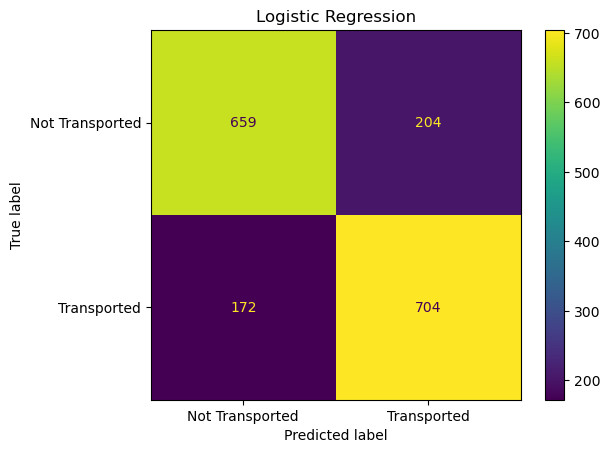

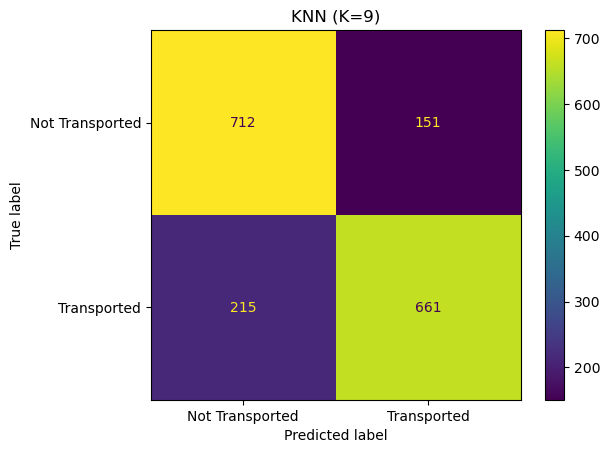

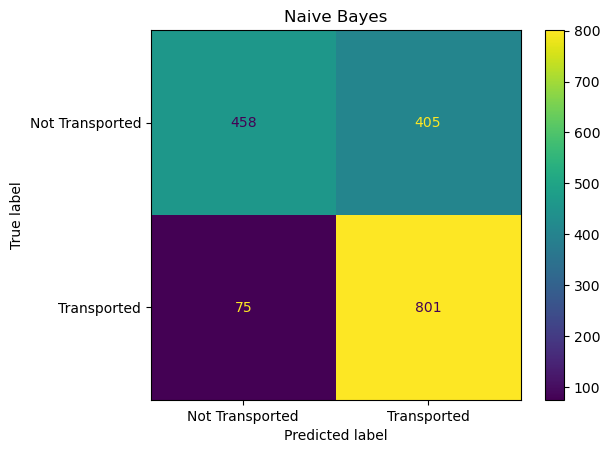

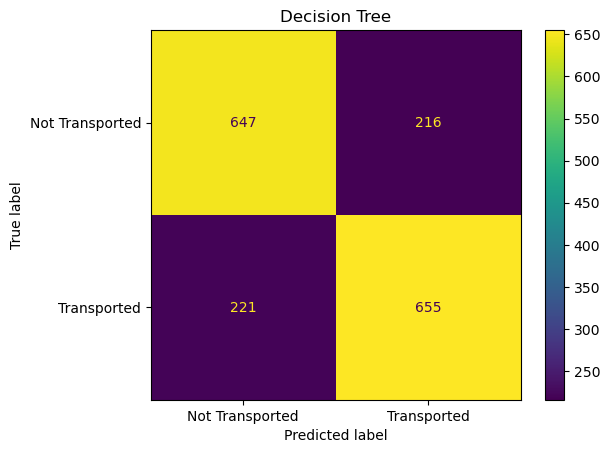

In [58]:
# Confusion matrices for all four models

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models = {
    "Logistic Regression": logistic_predictions_new,
    "KNN (K=9)": knn_predictions_new,
    "Naive Bayes": nb_predictions_new,
    "Decision Tree": decision_tree_predictions_new
}

for name, predictions in models.items():
    cm = confusion_matrix(y_test, predictions)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Transported", "Transported"]
    )

    display.plot()
    plt.title(name)
    plt.show()

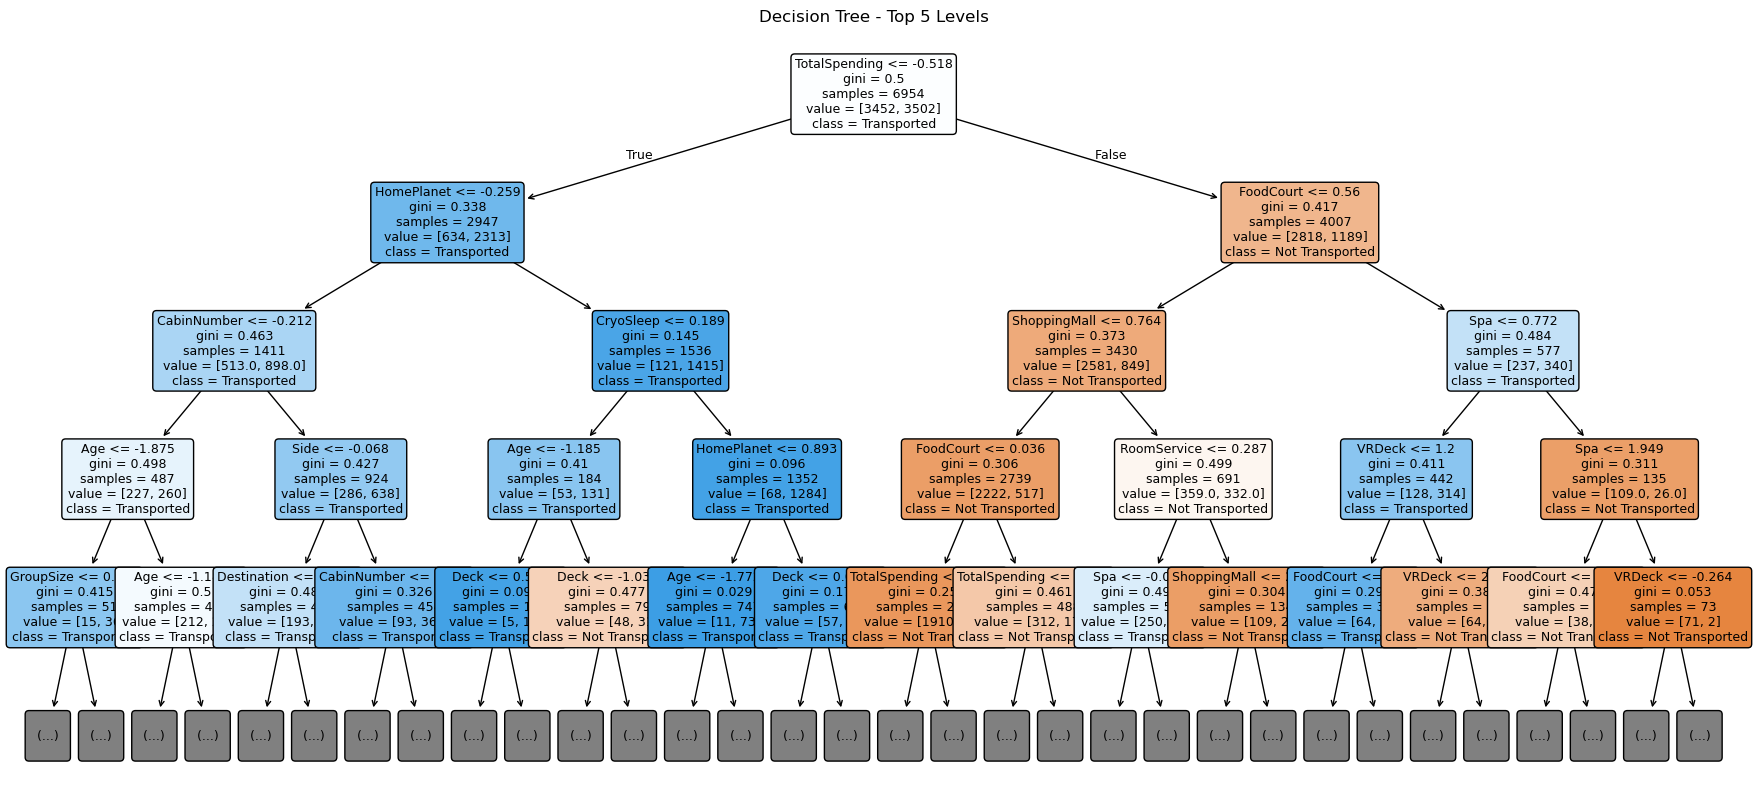

In [59]:
# Visualizing the top 5 levels of the Decision Tree

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(22, 10))

plot_tree(
    decision_tree_model_new,
    feature_names=X_train_final.columns,
    class_names=["Not Transported", "Transported"],
    filled=True,
    rounded=True,
    max_depth=4,
    fontsize=9
)

plt.title("Decision Tree - Top 5 Levels")
plt.show()

In [60]:
import pandas as pd
results = {
    'Model': [
        'Logistic Regression',
        'KNN (K=9)',
        'Naive Bayes',
        'Decision Tree'
    ],
    'Accuracy': [0.7838, 0.7895, 0.7240, 0.7487],
    'Precision': [0.7753, 0.8140, 0.6642, 0.7520],
    'Recall': [0.8037, 0.7546, 0.9144, 0.7477],
    'F1-Score': [0.7892, 0.7832, 0.7695, 0.7499]
}
results_df = pd.DataFrame(results)
results_df

## Findings and Insights

1. The dataset contains passenger information, travel details, and onboard spending, which were used to predict which passengers were transported to another dimension.
2. Data preprocessing included handling missing values, encoding categorical variables, and standardizing features.
3. Feature engineering introduced additional information, including group size, total spending, and a no-spending indicator.
4. Among the four models, **K-Nearest Neighbors (KNN), with K = 9, achieved the highest accuracy of 78.95%** and precision of 81.40%.
5. Logistic Regression achieved the highest F1-score of 78.92%, showing a good balance between precision and recall.
6. Gaussian Naive Bayes achieved the highest recall of 91.44%, making it effective at identifying transported passengers, although its overall accuracy was lower.
7. The Decision Tree achieved an accuracy of 74.87%. Its visualization helped illustrate how the model makes predictions using feature-based splits.
Overall, KNN was selected as the leading model based on accuracy, while the results show that model performance varies depending on the evaluation metric.

## Conclusion

This project aimed to predict whether passengers aboard the Spaceship Titanic were transported to another dimension using machine learning classification techniques. The dataset was preprocessed by handling missing values, encoding categorical features, and standardizing numerical data. Feature engineering was also performed to create additional features that could improve prediction.

Four classification models were implemented and evaluated: Logistic Regression, K-Nearest Neighbors, Gaussian Naive Bayes, and Decision Tree. Among these models, KNN with K = 9 achieved the highest accuracy of 78.95%, while Logistic Regression achieved the highest F1-score of 78.92%.

The results demonstrate that machine learning can identify patterns in passenger data and make useful predictions. However, model performance depends on the algorithm, preprocessing methods, and features used. The project also provided practical experience in data preprocessing, feature engineering, model evaluation, and visualization.